# Error analysis

**Research objective.** Analyze saved source-true/source-non-true errors without relabeling source data.

All results are read from local FNEWS artifacts. `SOURCE_TRUE` and `SOURCE_NON_TRUE` are Fakeddit source-taxonomy labels, not independently verified factuality labels. The held-out test partition is not opened by these notebooks except where a prior frozen metric is explicitly quoted.

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
if not (ROOT / "data/research_dataset").exists():
    ROOT = Path("/Users/aka_ank/Desktop/FNEWS")
DATA = ROOT / "data/research_dataset"
REPORTS = ROOT / "reports"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.titlesize": 13, "axes.labelsize": 11})

def paired(split):
    frame = pd.read_parquet(DATA / "manifests" / f"{split}_manifest.parquet")
    return frame.loc[(frame.source_dataset == "Fakeddit") & (frame.download_status == "verified_reused_or_processed")].copy().reset_index(drop=True)

def canonical_source_labels(raw):
    """Fakeddit raw 1=true; return 0=SOURCE_TRUE, 1=SOURCE_NON_TRUE."""
    return 1 - np.asarray(raw, dtype=int)

def source_names(values):
    return np.where(np.asarray(values) == 0, "SOURCE_TRUE", "SOURCE_NON_TRUE")

def show_frame(frame, rows=10):
    display(frame.head(rows))


## Active SVM errors

The corrected canonical matrix is `[[287, 90], [171, 385]]` in `[SOURCE_TRUE, SOURCE_NON_TRUE]` order. Correct label presentation did not change these raw predictions.

In [2]:
fn=pd.read_csv(REPORTS/'root_cause/svm_source_non_true_false_negatives.csv');fp=pd.read_csv(REPORTS/'root_cause/false_positive_manifest.csv');print('SOURCE_NON_TRUE → SOURCE_TRUE:',len(fn));print('SOURCE_TRUE → SOURCE_NON_TRUE:',len(fp));display(fn.head(10))

SOURCE_NON_TRUE → SOURCE_TRUE: 171
SOURCE_TRUE → SOURCE_NON_TRUE: 90


,sample_id,text,subreddit,domain,6_way_label,text_length,source_non_true_margin,failure_category
0,fakeddit:validate:3b9bxa,brazilian police with riot shields,misleadingthumbnails,i.imgur.com,2,34,-1.503464,source_non_true_to_true
1,fakeddit:validate:en2chek,this cat out of a box,psbattle_artwork,NaN,4,21,-1.488794,source_non_true_to_true
2,fakeddit:validate:cucs6vt,this,psbattle_artwork,NaN,4,4,-1.450561,source_non_true_to_true
3,fakeddit:validate:caeb30f,this,psbattle_artwork,NaN,4,4,-1.450561,source_non_true_to_true
4,fakeddit:validate:66plgc,former president barack obama spotted outside ...,fakehistoryporn,pbs.twimg.com,2,102,-1.281586,source_non_true_to_true
5,fakeddit:validate:7vtjnz,home of sexuals magnets,fakealbumcovers,i.redd.it,1,23,-1.269571,source_non_true_to_true
6,fakeddit:validate:47opgx,kizuna takahara when your roommate works at di...,subredditsimulator,imgur.com,3,72,-1.187837,source_non_true_to_true
7,fakeddit:validate:dzi2974,cat scan,psbattle_artwork,NaN,4,8,-1.181896,source_non_true_to_true
8,fakeddit:validate:au8e59,cat,misleadingthumbnails,i.redd.it,2,3,-1.181896,source_non_true_to_true
9,fakeddit:validate:911c67,robot peering out of an elevator shaft,misleadingthumbnails,i.redd.it,2,38,-1.154207,source_non_true_to_true


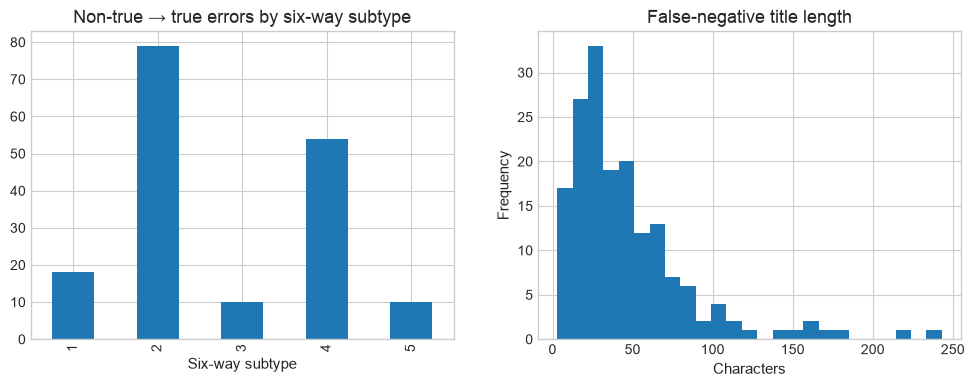

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4));fn['6_way_label'].value_counts().sort_index().plot.bar(ax=axes[0],title='Non-true → true errors by six-way subtype');axes[0].set_xlabel('Six-way subtype');fn.text_length.plot.hist(ax=axes[1],bins=25,title='False-negative title length');axes[1].set_xlabel('Characters');plt.show()

In [4]:
display(fn.groupby('subreddit').size().sort_values(ascending=False).head(12).rename('errors').to_frame());display(fn.sort_values('source_non_true_margin').head(12)[['text','subreddit','6_way_label','source_non_true_margin']])

,errors
subreddit,
psbattle_artwork,54
pareidolia,31
fakehistoryporn,25
misleadingthumbnails,15
subredditsimulator,10
confusing_perspective,8
fakealbumcovers,7
propagandaposters,6
satire,5


,text,subreddit,6_way_label,source_non_true_margin
0,brazilian police with riot shields,misleadingthumbnails,2,-1.503464
1,this cat out of a box,psbattle_artwork,4,-1.488794
2,this,psbattle_artwork,4,-1.450561
3,this,psbattle_artwork,4,-1.450561
4,former president barack obama spotted outside ...,fakehistoryporn,2,-1.281586
5,home of sexuals magnets,fakealbumcovers,1,-1.269571
6,kizuna takahara when your roommate works at di...,subredditsimulator,3,-1.187837
7,cat scan,psbattle_artwork,4,-1.181896
8,cat,misleadingthumbnails,2,-1.181896
9,robot peering out of an elevator shaft,misleadingthumbnails,2,-1.154207


## Interpretation

Failures include satire, misleading content, imposter content, false connection, and manipulation. Short titles and source-community style can limit lexical evidence. These labels are taxonomy categories, not universal fact-check outcomes; no record is relabeled in this notebook.